# Getaround - prédiction du prix de location
Objectif : donner aux utilisateurs de la plateforme une idée du prix auquel mettre leur voiture en location. 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Chargement

In [2]:
df = pd.read_csv("../Data/get_around_pricing_project.csv", index_col=0)
print(df.shape)
df.head()

(4843, 14)


,model_key,mileage,engine_power,fuel,paint_color,car_type,private_parking_available,has_gps,has_air_conditioning,automatic_car,has_getaround_connect,has_speed_regulator,winter_tires,rental_price_per_day
0,Citroën,140411,100,diesel,black,convertible,True,True,False,False,True,True,True,106
1,Citroën,13929,317,petrol,grey,convertible,True,True,False,False,False,True,True,264
2,Citroën,183297,120,diesel,white,convertible,False,False,False,False,True,False,True,101
3,Citroën,128035,135,diesel,red,convertible,True,True,False,False,True,True,True,158
4,Citroën,97097,160,diesel,silver,convertible,True,True,False,False,False,True,True,183


## Structure

In [3]:
df.info()
print(df.isna().sum().sum(), "valeurs manquantes")
print(df.duplicated().sum(), "doublons")

<class 'pandas.DataFrame'>
RangeIndex: 4843 entries, 0 to 4842
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   model_key                  4843 non-null   str  
 1   mileage                    4843 non-null   int64
 2   engine_power               4843 non-null   int64
 3   fuel                       4843 non-null   str  
 4   paint_color                4843 non-null   str  
 5   car_type                   4843 non-null   str  
 6   private_parking_available  4843 non-null   bool 
 7   has_gps                    4843 non-null   bool 
 8   has_air_conditioning       4843 non-null   bool 
 9   automatic_car              4843 non-null   bool 
 10  has_getaround_connect      4843 non-null   bool 
 11  has_speed_regulator        4843 non-null   bool 
 12  winter_tires               4843 non-null   bool 
 13  rental_price_per_day       4843 non-null   int64
dtypes: bool(7), int64(3), str(4)
memory

In [5]:
target = "rental_price_per_day"
num_cols = ["mileage", "engine_power"]
cat_cols = ["model_key", "fuel", "paint_color", "car_type"]
bool_cols = ["private_parking_available", "has_gps", "has_air_conditioning",
             "automatic_car", "has_getaround_connect", "has_speed_regulator", "winter_tires"]

## Cible

count    4843.000000
mean      121.214536
std        33.568268
min        10.000000
25%       104.000000
50%       119.000000
75%       136.000000
max       422.000000
Name: rental_price_per_day, dtype: float64


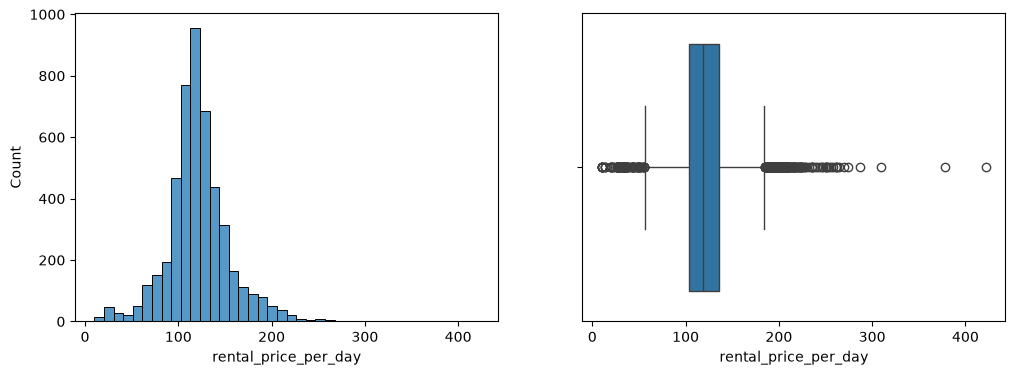

In [6]:
print(df[target].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[target], bins=40, ax=axes[0])
sns.boxplot(x=df[target], ax=axes[1])
plt.show()

## Variables numeriques

            mileage  engine_power
count  4.843000e+03    4843.00000
mean   1.409628e+05     128.98823
std    6.019674e+04      38.99336
min   -6.400000e+01       0.00000
25%    1.029135e+05     100.00000
50%    1.410800e+05     120.00000
75%    1.751955e+05     135.00000
max    1.000376e+06     423.00000


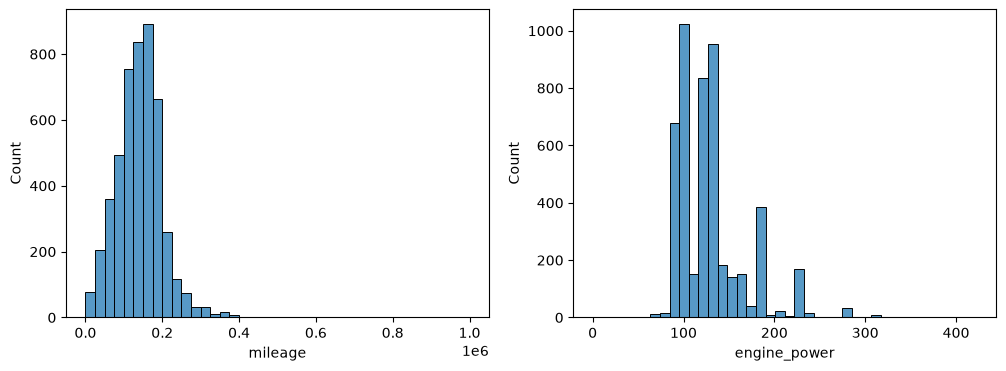

In [7]:
print(df[num_cols].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], bins=40, ax=ax)
plt.show()

In [8]:
# valeurs suspectes (kilometrage negatif, puissance nulle)
df[(df["mileage"] <= 0) | (df["engine_power"] <= 0) | (df["mileage"] > 400_000)].sort_values("mileage")

,model_key,mileage,engine_power,fuel,paint_color,car_type,private_parking_available,has_gps,has_air_conditioning,automatic_car,has_getaround_connect,has_speed_regulator,winter_tires,rental_price_per_day
2938,Renault,-64,230,diesel,black,sedan,True,True,False,True,False,False,True,274
3765,Nissan,81770,0,diesel,white,suv,False,False,False,False,False,False,False,108
1573,Citroën,400654,110,diesel,black,estate,False,False,True,False,False,False,True,42
3198,Citroën,405816,100,diesel,blue,sedan,False,False,False,False,False,False,True,22
2829,Audi,439060,105,diesel,silver,sedan,False,False,True,False,False,False,True,10
2350,Peugeot,477571,85,diesel,grey,hatchback,False,True,False,False,False,True,False,35
557,Renault,484615,120,diesel,blue,estate,True,True,False,False,False,False,True,91
3732,Citroën,1000376,90,diesel,black,subcompact,True,False,False,False,False,False,True,37


valeurs aberrantes : mileage = -64, engine_power = 0, mileage = 1 000 376 --> 3 lignes à supprimer.

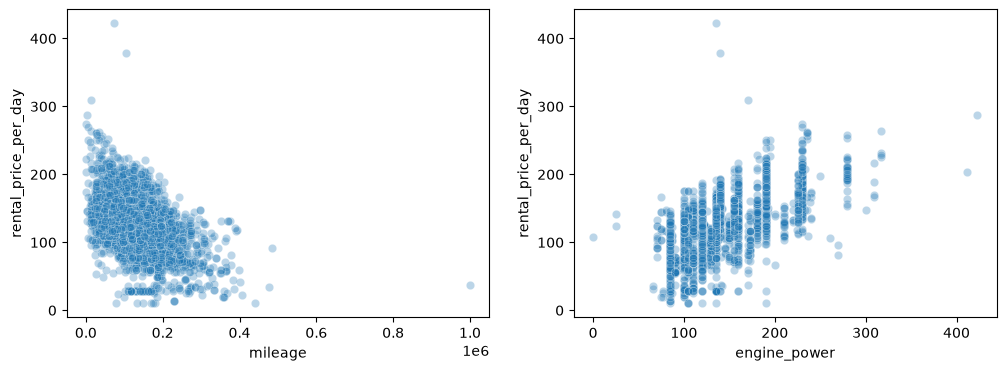

mileage                -0.448912
engine_power            0.625645
rental_price_per_day    1.000000
Name: rental_price_per_day, dtype: float64

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, num_cols):
    sns.scatterplot(data=df, x=col, y=target, alpha=0.3, ax=ax)
plt.show()

df[num_cols + [target]].corr()[target]

## Variables categorielles

In [12]:
df[cat_cols].nunique()

model_key      28
fuel            4
paint_color    10
car_type        8
dtype: int64

In [10]:
for col in cat_cols:
    print(df[col].value_counts(), "\n")

model_key
Citroën        969
Renault        916
BMW            827
Peugeot        642
Audi           526
Nissan         275
Mitsubishi     231
Mercedes        97
Volkswagen      65
Toyota          53
SEAT            46
Subaru          44
PGO             33
Opel            33
Ferrari         33
Maserati        18
Suzuki           8
Porsche          6
Ford             5
KIA Motors       3
Alfa Romeo       3
Fiat             2
Lamborghini      2
Lexus            2
Honda            1
Mazda            1
Mini             1
Yamaha           1
Name: count, dtype: int64 

fuel
diesel           4641
petrol            191
hybrid_petrol       8
electro             3
Name: count, dtype: int64 

paint_color
black     1633
grey      1175
blue       710
white      538
brown      341
silver     329
red         52
beige       41
green       18
orange       6
Name: count, dtype: int64 

car_type
estate         1606
sedan          1168
suv            1058
hatchback       699
subcompact      117
coupe     

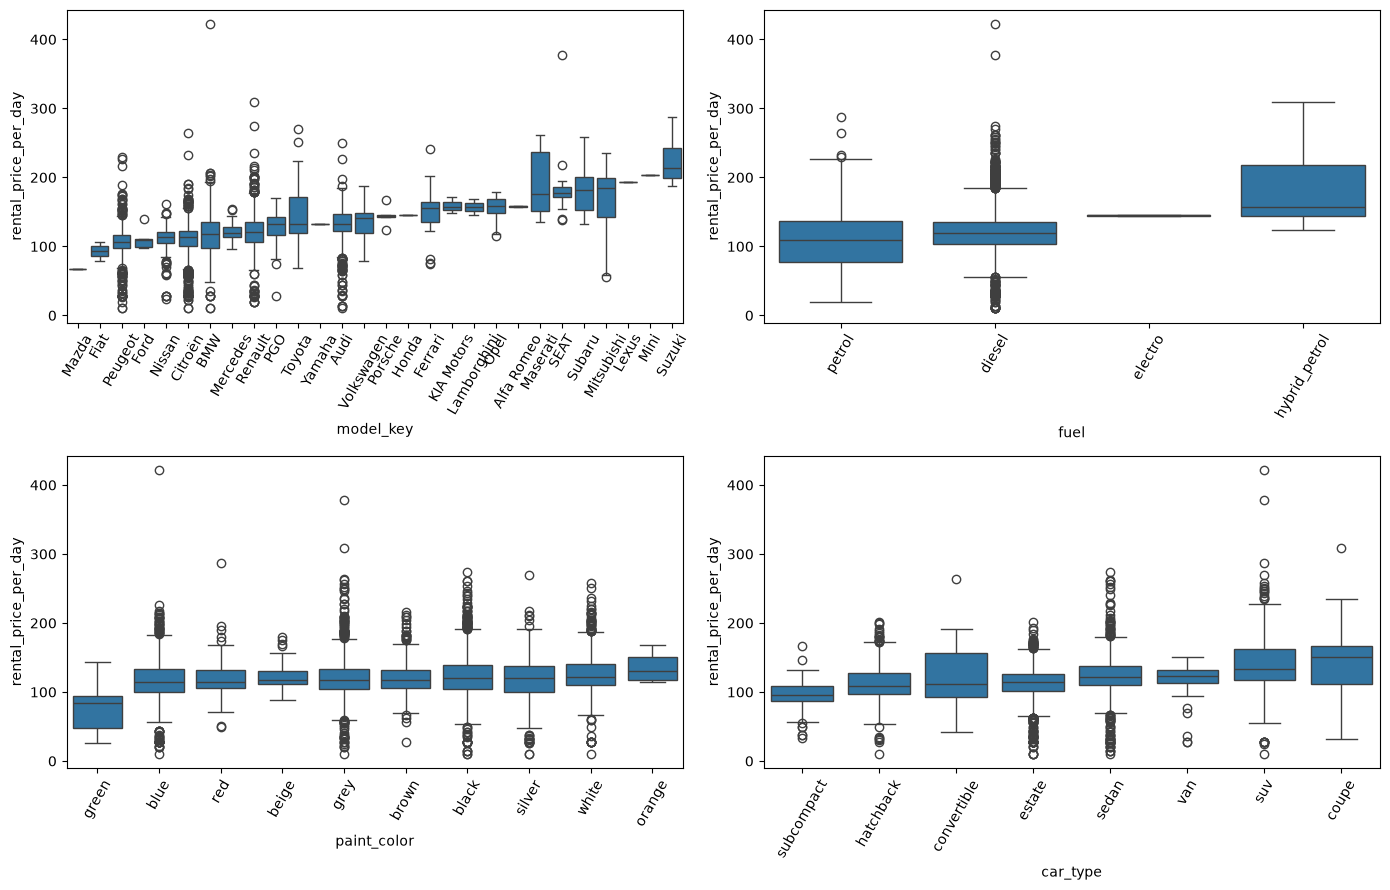

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), cat_cols):
    order = df.groupby(col)[target].median().sort_values().index
    sns.boxplot(data=df, x=col, y=target, order=order, ax=ax)
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

In [14]:
df.groupby("paint_color")[target].agg(["count", "mean"]).round(0).sort_values("mean")

,count,mean
paint_color,,
green,18,78.0
silver,329,116.0
blue,710,118.0
grey,1175,120.0
brown,341,121.0
red,52,123.0
black,1633,123.0
beige,41,124.0
white,538,127.0


La couleur semble avoir peut d'effet sur le prix --> voir si on garde ou pas ce critère ?

## Variables booleennes

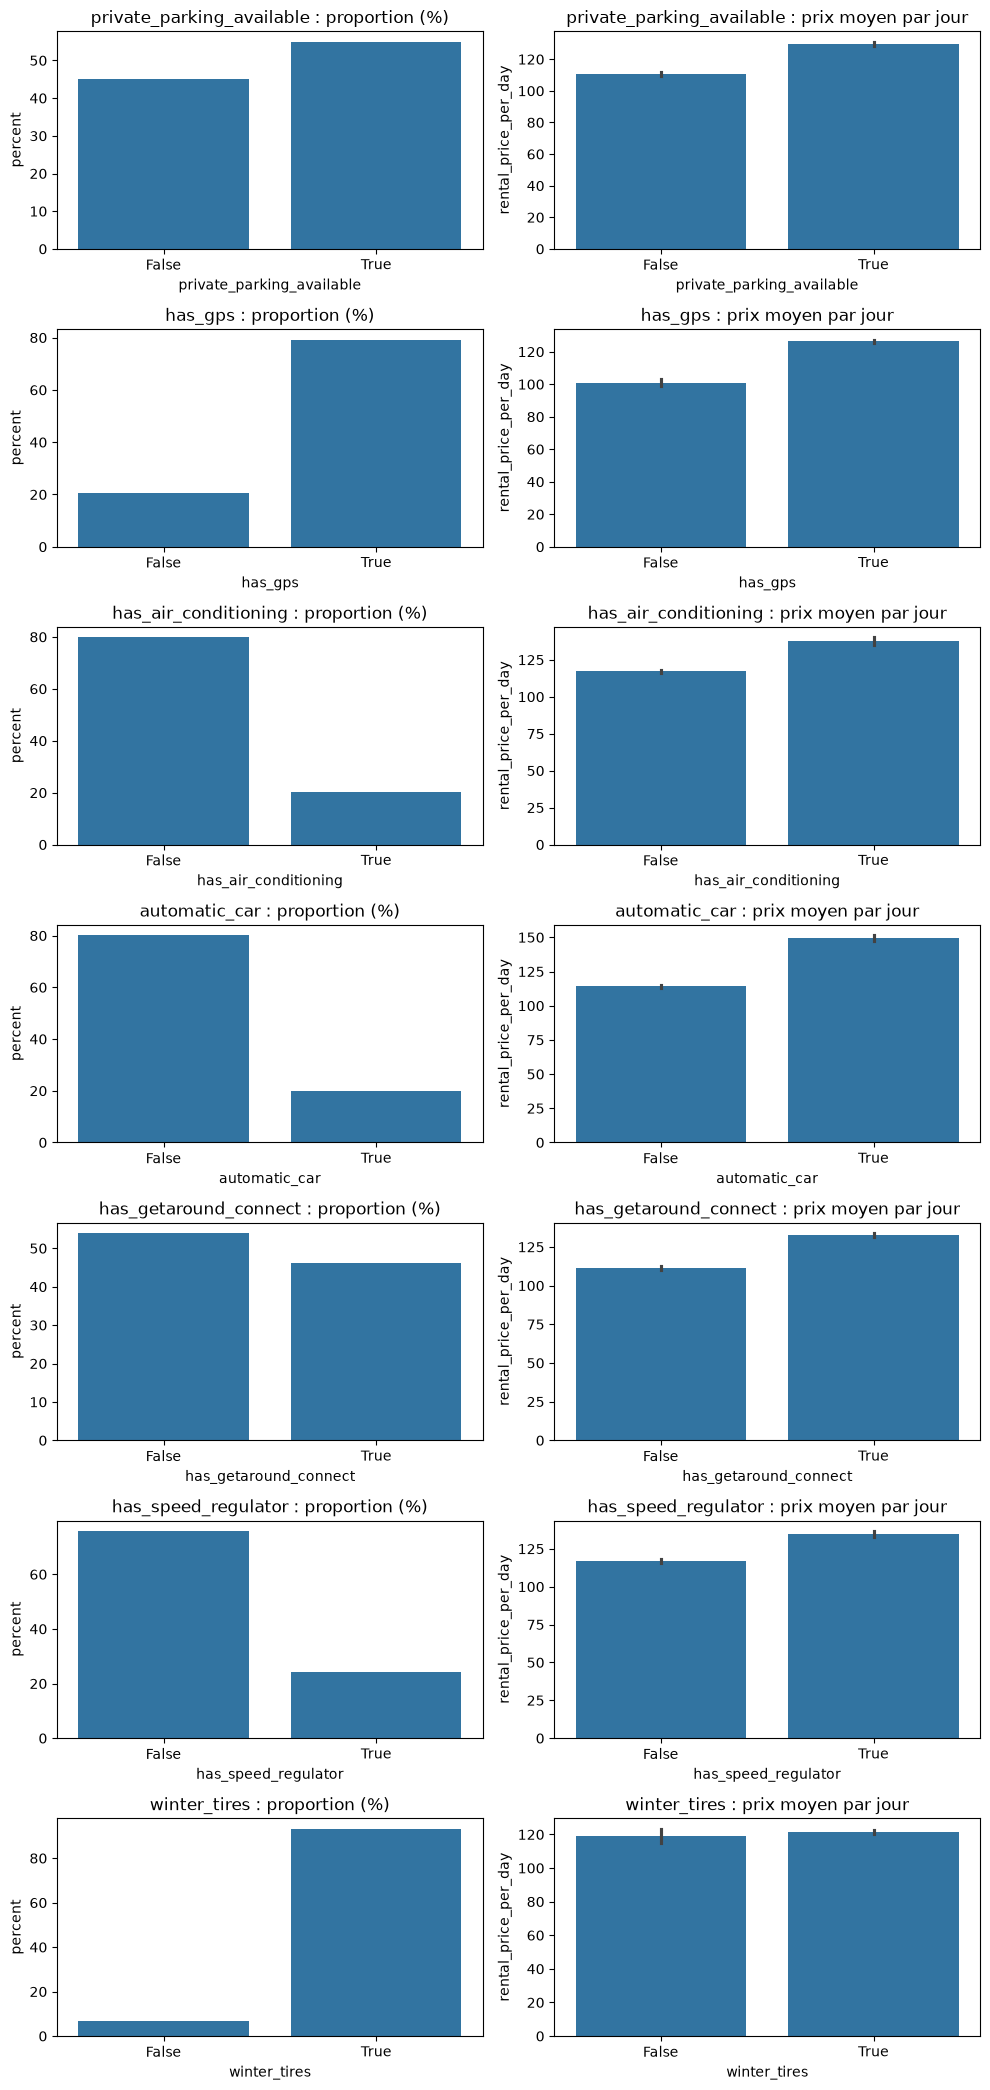

In [21]:
fig, axes = plt.subplots(len(bool_cols), 2, figsize=(10, 3 * len(bool_cols)))
for i, col in enumerate(bool_cols):
    sns.countplot(data=df, x=col, stat="percent", ax=axes[i, 0])
    axes[i, 0].set_title(f"{col} : proportion (%)")
    sns.barplot(data=df, x=col, y=target, ax=axes[i, 1])
    axes[i, 1].set_title(f"{col} : prix moyen par jour")
plt.tight_layout()
plt.show()

In [15]:
rows = []
for col in bool_cols:
    m = df.groupby(col)[target].mean()
    rows.append({"option": col, "part_True_%": round(df[col].mean() * 100, 1),
                 "ecart_prix": round(m[True] - m[False], 1)})
pd.DataFrame(rows).set_index("option").sort_values("ecart_prix")

,part_True_%,ecart_prix
option,,
winter_tires,93.2,2.4
has_speed_regulator,24.1,17.8
private_parking_available,55.0,19.0
has_air_conditioning,20.2,20.5
has_getaround_connect,46.0,21.4
has_gps,79.3,25.7
automatic_car,19.9,35.3


winter_tires : a priori peu d'incidence sur le résultat --> voir si on garde ?

## Correlations

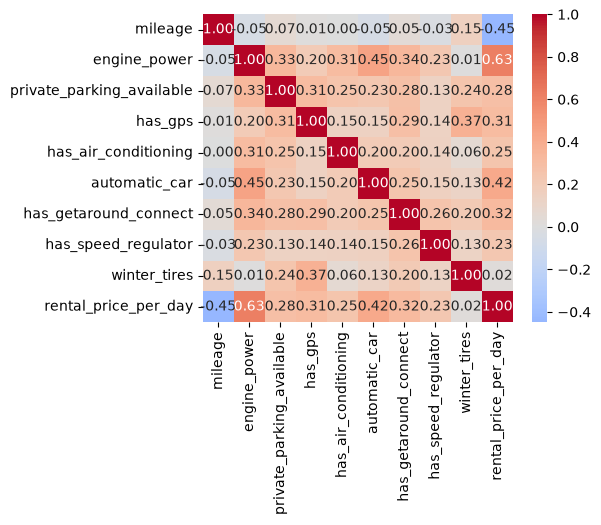

In [23]:
plt.figure(figsize=(5, 4))
sns.heatmap(df[num_cols + bool_cols + [target]].astype(float).corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

Les variables incontournables : kilométrage, puissance moteur.
On peut supprimer les pneus hiver.

## Nettoyage et choix des colonnes

In [25]:
df_clean = df[(df["mileage"] > 0) & (df["engine_power"] > 0) & (df["mileage"] <= 600_000)].copy()
print(len(df) - len(df_clean), "lignes supprimees")
print(len(df_clean), "lignes restantes")


3 lignes supprimees
4840 lignes restantes


In [26]:
features = num_cols + cat_cols + bool_cols

X = df_clean[features]
y = df_clean[target]
print(X.shape, y.shape)

(4840, 13) (4840,)


In [40]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GridSearchCV

In [29]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=42)

print(X_tr.shape, X_val.shape, X_test.shape)

(2904, 13) (968, 13) (968, 13)


In [31]:
preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
], remainder="passthrough")

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(random_state=42)),
])

model.fit(X_tr, y_tr)
print("R2 train :", round(model.score(X_tr, y_tr), 3))
print("R2 val   :", round(model.score(X_val, y_val), 3))

R2 train : 0.962
R2 val   : 0.793


In [35]:
result = permutation_importance(model, X_val, y_val, n_repeats=10, random_state=42, scoring="r2")

importances = pd.DataFrame({
    "variable": X_val.columns,
    "baisse_r2": result.importances_mean.round(4),
    "ecart_type": result.importances_std.round(4),
}).sort_values("baisse_r2", ascending=False)

importances

,variable,baisse_r2,ecart_type
1,engine_power,0.6464,0.0244
0,mileage,0.3627,0.0199
2,model_key,0.0691,0.0054
7,has_gps,0.0581,0.0056
5,car_type,0.0470,0.0046
10,has_getaround_connect,0.0284,0.0032
3,fuel,0.0198,0.0021
9,automatic_car,0.0115,0.0018
4,paint_color,0.0103,0.0074
12,winter_tires,0.0069,0.0022


on garde toutes les colonnes, mais on prévoit un simpleImputer au cas où il manquerait des infos à l'utilisateur. Les valeurs de kilométrage et de puissance moteur restent indispensables pour faire la prédiction.

In [ ]:
X = df_clean[features].copy()
X[bool_cols] = X[bool_cols].astype(float) #pour le SimpleImputer
y = df_clean[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=42)

print(X_tr.shape, X_val.shape, X_test.shape)

(2904, 13) (968, 13) (968, 13)


In [39]:
preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("encoder", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
    ("bool", SimpleImputer(strategy="most_frequent"), bool_cols),
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(random_state=42)),
])

model.fit(X_tr, y_tr)
print("R2 train :", round(model.score(X_tr, y_tr), 3))
print("R2 val   :", round(model.score(X_val, y_val), 3))

R2 train : 0.962
R2 val   : 0.793


In [41]:
pipe = Pipeline(steps=[("preprocessor", preprocessor),
                       ("regressor", RandomForestRegressor(random_state=42))])

param_grid = {
    "regressor__n_estimators": [100, 300],
    "regressor__max_depth": [None, 10, 20],
    "regressor__min_samples_leaf": [1, 3, 5],
}

grid = GridSearchCV(pipe, param_grid=param_grid, cv=5,
                    scoring="neg_mean_absolute_error", n_jobs=-1)
grid.fit(X_train, y_train)

best = grid.best_index_
print("meilleurs paramètres :", grid.best_params_)
print("MAE validation croisée :", round(-grid.best_score_, 2))
print("écart-type :", round(grid.cv_results_["std_test_score"][best], 2))

meilleurs paramètres : {'regressor__max_depth': 20, 'regressor__min_samples_leaf': 1, 'regressor__n_estimators': 300}
MAE validation croisée : 10.63
écart-type : 0.45
